# Keypoint estimation — train and evaluate

Training is one call; the interesting part is *reading what comes out*. This notebook trains, plots the learning curves, evaluates on the test split, and shows you how to interpret each number.

In [1]:
# Run this cell first.
# On Colab it clones the kit and installs what's missing; locally it just finds the repo root.
import os, sys, subprocess
from pathlib import Path

if "google.colab" in sys.modules and not Path("cvkit").exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/standungan/computer-vision-starter-kit"], check=True)
    os.chdir("computer-vision-starter-kit")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyyaml", "scikit-learn", "gradio"], check=True)
while not Path("cvkit").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)          # notebooks live 3 folders below the repo root
sys.path.insert(0, os.getcwd())
print("working in", Path.cwd().name)

working in computer-vision-starter-kit


In [2]:
%config InlineBackend.figure_format = "jpeg"
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 90}}   # keeps saved notebooks small

from PIL import Image

from cvkit.config import load_config
from cvkit.synthetic import make_demo_data
from cvkit.utils import seed_everything

# quick.yaml = small synthetic demo, runs on a laptop CPU in minutes.
# Swap in default.yaml (bigger, pretrained) or your own config + data when you're ready.
CONFIG = "tasks/keypoints/configs/quick.yaml"
cfg = load_config(CONFIG)
seed_everything(cfg["seed"])

if not Path(cfg["data"]["root"]).exists():          # first run: create the demo dataset
    make_demo_data("keypoints", cfg)
print("task:", "keypoints", "| data:", cfg["data"]["root"], "| outputs:", cfg["output"]["dir"])

task: keypoints | data: data/demo/keypoints | outputs: outputs/keypoints_quick


## The configuration
Everything tunable is in one YAML file. These are the sections that matter:

In [3]:
import yaml

for section in ('data', 'model', 'train'):
    print(section + ':')
    for line in yaml.safe_dump(cfg[section], sort_keys=False).splitlines():
        print('  ' + line)

data:
  root: data/demo/keypoints
  images_dir: images
  annotations: annotations.json
  image_size: 128
  batch_size: 16
  num_workers: 0
  split:
    train: 0.7
    val: 0.15
    test: 0.15
  augment:
    rotation: 15
    translate: 0.08
    scale:
    - 0.9
    - 1.1
    color_jitter: 0.1
model:
  arch: resnet18
  pretrained: false
  heatmap_sigma: 2.0
train:
  epochs: 20
  lr: 0.002
  weight_decay: 0.0001
  amp: true
  early_stopping_patience: 0


## What are we about to train?

In [4]:
import torch
from cvkit.utils import count_parameters
from tasks.keypoints.data import build_loaders
from tasks.keypoints.model import build_model

names = build_loaders(cfg)["keypoint_names"]
model = build_model(cfg, {"keypoint_names": names})
p = count_parameters(model)
size = cfg["data"]["image_size"]
out = model.eval()(torch.randn(1, 3, size, size))
print(f"arch {cfg['model']['arch']} | pretrained {cfg['model']['pretrained']} | {len(names)} keypoints: {names}")
print(f"{p['total']:,} parameters | input (1,3,{size},{size}) -> heatmaps {tuple(out.shape)}")
del model

arch resnet18 | pretrained False | 3 keypoints: ['apex', 'left', 'right']
15,373,123 parameters | input (1,3,128,128) -> heatmaps (1, 3, 32, 32)


## Train
Watch the `val` numbers: they are what picks the best epoch.

In [5]:
from tasks.keypoints.train import train

result = train(cfg)
print('\nbest epoch:', result['best_epoch'], '|', {k: round(v, 4) for k, v in result['best_metrics'].items()})

arch: resnet18 | keypoints (3): ['apex', 'left', 'right']
device: cpu | parameters: 15,373,123 total, 15,373,123 trainable (100.0%)


epoch   1/20 | train_loss 6.9139 | val nme=0.129 pck=0.132 mean_err_px=16.454 | 5.1s  <- best


epoch   2/20 | train_loss 5.5562 | val nme=0.085 pck=0.236 mean_err_px=10.818 | 4.9s  <- best


epoch   3/20 | train_loss 4.9111 | val nme=0.047 pck=0.611 mean_err_px=5.979 | 5.0s  <- best


epoch   4/20 | train_loss 4.5452 | val nme=0.034 pck=0.792 mean_err_px=4.336 | 4.8s  <- best


...

epoch  16/20 | train_loss 4.1964 | val nme=0.008 pck=1.000 mean_err_px=1.060 | 4.8s  <- best


epoch  17/20 | train_loss 4.2002 | val nme=0.009 pck=1.000 mean_err_px=1.096 | 5.1s


epoch  18/20 | train_loss 4.1998 | val nme=0.008 pck=1.000 mean_err_px=0.999 | 4.9s  <- best


epoch  19/20 | train_loss 4.1893 | val nme=0.008 pck=1.000 mean_err_px=0.991 | 4.6s  <- best


epoch  20/20 | train_loss 4.2012 | val nme=0.008 pck=1.000 mean_err_px=1.011 | 4.8s
best val nme = 0.0077 (epoch 19) -> outputs/keypoints_quick/checkpoints/best.pt

best epoch: 19 | {'nme': 0.0077, 'pck': 1.0, 'mean_err_px': 0.9907}


## Learning curves
Validation panels show **nme** (normalised error: lower is better, it picked the best epoch), **pck** (higher is better) and the mean error in pixels. The training loss is on the left. Note it flattens at a value well above 0 (about 4 here): cross-entropy against a blob has a *floor* equal to the blob's own entropy, so a flat loss does not mean learning stopped — watch the validation error instead. **Gap widening** between train and val → overfitting (more augmentation, fewer epochs, smaller model). **Both flat and poor** → underfitting (train longer, raise the learning rate, unfreeze the backbone). **Val bouncing hard** → learning rate too high, or the val split is small. Remember the quick preset trains for only a few epochs, so expect curves still on their way up.

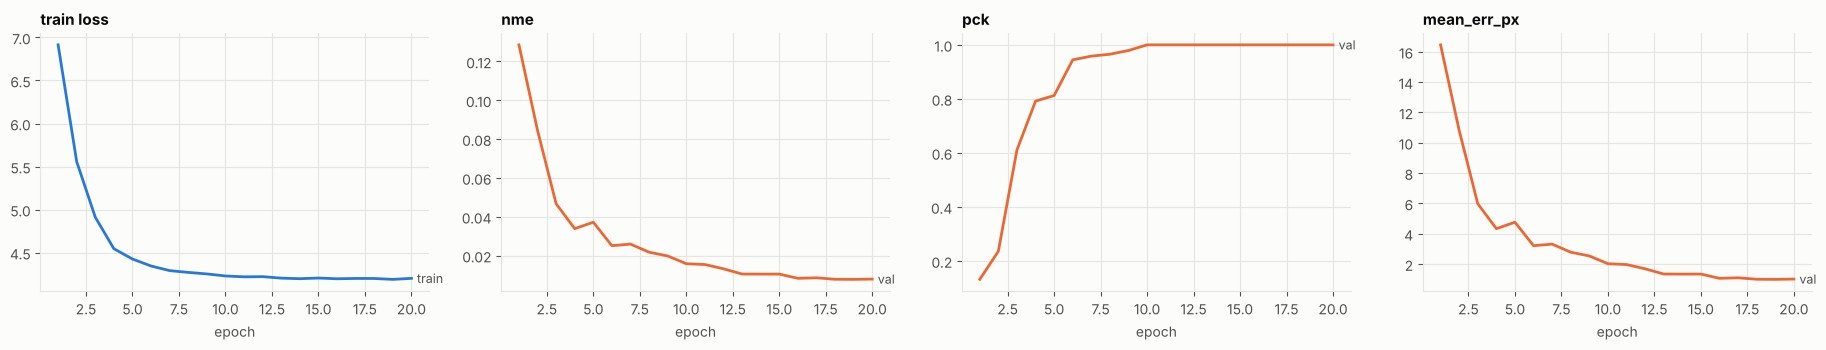

In [6]:
from cvkit.viz import plot_history

_ = plot_history(Path(cfg['output']['dir']) / 'history.csv')

## Evaluate on the test split
Val chose the checkpoint; the **test split** was untouched until now, so it is the honest number. One rule: look at test results, *don't tune on them* — the moment you tweak settings to chase the test score, it stops measuring generalisation.

In [7]:
from tasks.keypoints.evaluate import evaluate

metrics = evaluate(cfg)

NME 0.0080 (of image side) | mean error 1.02px at 128px | PCK@0.05 1.000 (48 test images)
  apex           PCK 1.000   NME 0.0068
  left           PCK 1.000   NME 0.0086
  right          PCK 1.000   NME 0.0087
reports -> outputs/keypoints_quick/reports


pck_curve.png


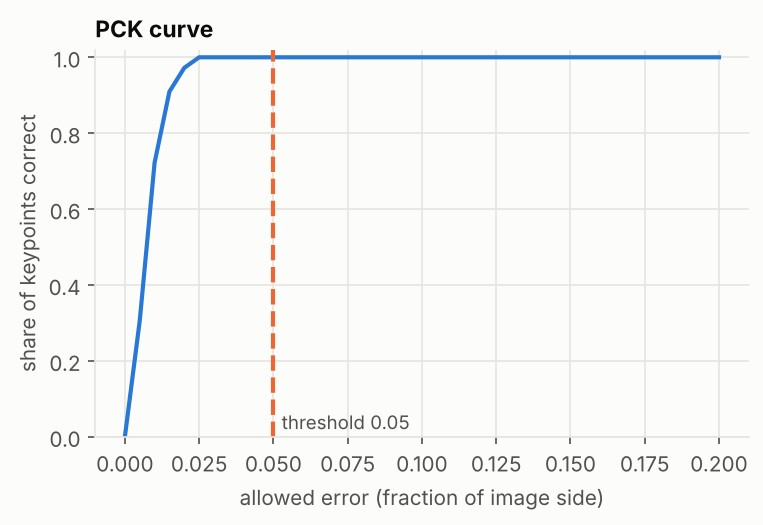

error_per_keypoint.png


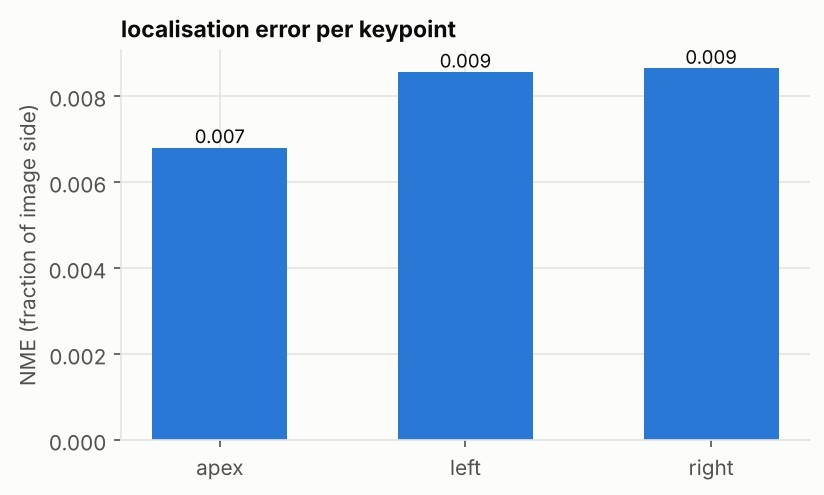

predictions.png


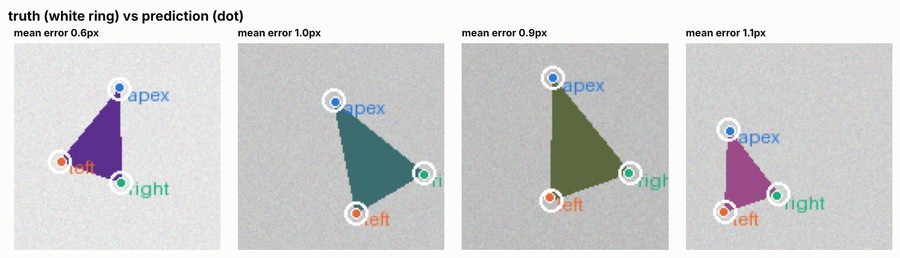

worst_images.png


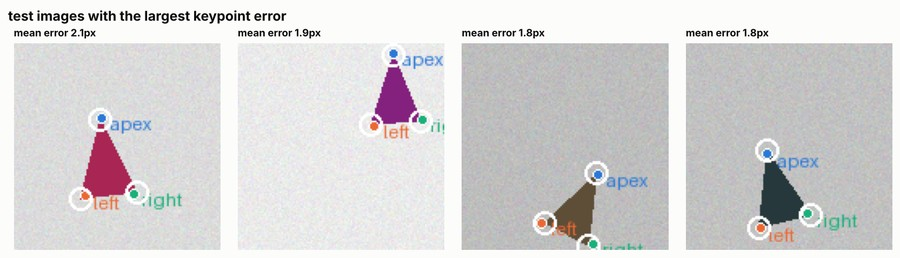

In [8]:
from cvkit.viz import show_image

reports = Path(cfg["output"]["dir"]) / "reports"
for name in ['pck_curve.png', 'error_per_keypoint.png', 'predictions.png', 'worst_images.png']:
    print(name)
    show_image(reports / name)

## How to read these results
* **NME (normalised mean error)** — average distance between predicted and true points, as a fraction of the image side. Resolution-independent; lower is better.
* **Mean error in pixels** — the same distance in input pixels, easier to picture.
* **PCK@threshold** — the share of keypoints within `eval.pck_threshold` × image side of the truth. "95% of points are within 5% of the image" is an easy sentence to say.
* **PCK curve** — PCK as the allowed distance grows. A curve that rises steeply near zero means precise points; a slow climb means sloppy ones.
* **Error per keypoint** — one landmark is usually the hard one (often the symmetric or the often-hidden one).
* **Worst images** — left/right confusions, points snapped to the wrong similar-looking feature, or objects partly out of frame.

## Experiments worth running
Each one is a one-line change. Re-run the training cell with a different config and compare the best val numbers (change `cfg` like this, then re-run from *Train*):

```python
cfg['model']['arch'] = 'resnet34'     # or any key, same as --set model.arch=resnet34
```

1. `data.augment.rotation = 0` — what does rotation augmentation buy?
2. `model.heatmap_sigma = 1` vs `3` — sharper or softer targets
3. `data.image_size = 192` — finer heatmaps, slower
4. `model.arch = 'resnet34'` — does capacity help?

Change **one thing at a time**, keep the seed, and write down what you changed — otherwise you can't tell what helped.

Next: **[03_predict_and_deploy](03_predict_and_deploy.ipynb)**.